In [1]:
import math
import random
import statistics
import time
import matplotlib.pyplot as plt

POPULATION_SIZE = 10
ITERATIONS = 50
NUM_RUNS = 50
SEED = 42
R_MAX = 1.2
MUTATION_RATE_MIN = 0.1
MUTATION_RATE_MAX = 0.5
STAGNATION_LIMIT = 5
IMPROVEMENT_TOLERANCE = 1e-6
LOCAL_CHILDREN = 5
FINEST_DECADE = 6

In [2]:
def f1(x):
    return 10 - (x - 3)**2

def f2(x):
    return 10 - (-x * math.sin(math.sqrt(abs(x))) + 418.9828872724337)

def f3(x):
    return 10 - (x**2 - 10 * math.cos(2 * math.pi * x) + 10)

FUNCTIONS = {
    "f1": (f1, -5, 10, 10),
    "f2": (f2, -500, 500, 10),
    "f3": (f3, -5.12, 5.12, 10),
}

In [3]:
def run_improved(population, objective_function, lower, upper):
    mutation_std = 0.1 * (upper - lower)
    populations = [population]
    values = [objective_function(x) for x in population]
    top = max(range(len(population)), key=values.__getitem__)
    best_x, best_f = population[top], values[top]
    history = [best_f]
    stagnation = 0

    for _ in range(ITERATIONS):
        if stagnation >= STAGNATION_LIMIT:
            top = max(range(len(population)), key=values.__getitem__)
            population = [population[top]] + [
                random.uniform(lower, upper) for _ in range(POPULATION_SIZE - 1)
            ]
            values = [objective_function(x) for x in population]
            stagnation = 0

        spread = (max(population) - min(population)) / (upper - lower)
        mutation_rate = MUTATION_RATE_MIN + (MUTATION_RATE_MAX - MUTATION_RATE_MIN) * (1 - min(1, spread))
        top = max(range(len(population)), key=values.__getitem__)
        new_population = list(population)
        new_values = list(values)
        for _ in range(POPULATION_SIZE):
            ia, ib, ic = random.sample(range(len(population)), 3)
            c = (population[ia] + population[ib] + population[ic]) / 3
            ip = ia
            if values[ib] > values[ip]:
                ip = ib
            if values[ic] > values[ip]:
                ip = ic
            r = random.uniform(0, R_MAX)
            xnew = c + r * (population[ip] - c)

            if random.random() < mutation_rate:
                xnew += random.gauss(0, mutation_std)

            xnew = max(lower, min(upper, xnew))
            fnew = objective_function(xnew)
            if fnew > new_values[ip]:
                new_population[ip] = xnew
                new_values[ip] = fnew

        for _ in range(LOCAL_CHILDREN):
            scale = (upper - lower) * 10 ** (-random.uniform(1, FINEST_DECADE))
            xnew = best_x + random.gauss(0, scale)
            xnew = max(lower, min(upper, xnew))
            fnew = objective_function(xnew)
            if fnew > new_values[top]:
                new_population[top] = xnew
                new_values[top] = fnew

        population, values = new_population, new_values
        populations.append(population)

        previous_best = best_f
        top = max(range(len(population)), key=values.__getitem__)
        if values[top] > best_f:
            best_x, best_f = population[top], values[top]

        if best_f > previous_best + IMPROVEMENT_TOLERANCE:
            stagnation = 0
        else:
            stagnation += 1

        history.append(best_f)

    return {
        "best_x": best_x,
        "best_f": best_f,
        "history": history,
        "populations": populations
    }

In [4]:
def initial_population(lower, upper):
    width = (upper - lower) / POPULATION_SIZE
    return [
        random.uniform(lower + k * width, lower + (k + 1) * width)
        for k in range(POPULATION_SIZE)
    ]

results = {}
execution_times = {}
for name, (objective, lower, upper, optimum) in FUNCTIONS.items():
    random.seed(SEED)
    start_time = time.perf_counter()
    results[name] = [
        run_improved(initial_population(lower, upper), objective, lower, upper)
        for _ in range(NUM_RUNS)
    ]
    execution_times[name] = time.perf_counter() - start_time

In [5]:
best_values = {}
for function, runs in results.items():
    print(f"BEST SOLUTION OF EACH RUN: {function}")
    print(f"{'Run':>5} {'Best x':>12} {'Best f(x)':>12}")
    print("-" * 31)

    for run, result in enumerate(runs, start=1):
        print(
            f"{run:>5} "
            f"{result['best_x']:>12.4f} "
            f"{result['best_f']:>12.6f}"
        )
    print()

    best_values[function] = [result["best_f"] for result in runs]

BEST SOLUTION OF EACH RUN: f1
  Run       Best x    Best f(x)
-------------------------------
    1       3.0000    10.000000
    2       3.0000    10.000000
    3       3.0000    10.000000
    4       3.0000    10.000000
    5       3.0000    10.000000
    6       3.0000    10.000000
    7       3.0000    10.000000
    8       3.0000    10.000000
    9       3.0000    10.000000
   10       3.0000    10.000000
   11       3.0000    10.000000
   12       3.0000    10.000000
   13       3.0000    10.000000
   14       3.0000    10.000000
   15       3.0000    10.000000
   16       3.0000    10.000000
   17       3.0000    10.000000
   18       3.0000    10.000000
   19       3.0000    10.000000
   20       3.0000    10.000000
   21       3.0000    10.000000
   22       3.0000    10.000000
   23       3.0000    10.000000
   24       3.0000    10.000000
   25       3.0000    10.000000
   26       3.0000    10.000000
   27       3.0000    10.000000
   28       3.0000    10.000000
   29     

In [6]:
for function, values in best_values.items():
    print(f"EVALUATION METRICS: {function}")
    print(f"Best overall  : {max(values):.6f}")
    print(f"Average best  : {statistics.mean(values):.6f}")
    print(f"Worst overall : {min(values):.6f}")
    print(f"Std of best   : {statistics.stdev(values):.6f}")
    print(f"Time ({NUM_RUNS} runs) : {execution_times[function]:.4f} s")
    print()

EVALUATION METRICS: f1
Best overall  : 10.000000
Average best  : 10.000000
Worst overall : 10.000000
Std of best   : 0.000000
Time (50 runs) : 0.0934 s

EVALUATION METRICS: f2
Best overall  : 10.000000
Average best  : 10.000000
Worst overall : 9.999991
Std of best   : 0.000001
Time (50 runs) : 0.0969 s

EVALUATION METRICS: f3
Best overall  : 10.000000
Average best  : 10.000000
Worst overall : 10.000000
Std of best   : 0.000000
Time (50 runs) : 0.0980 s



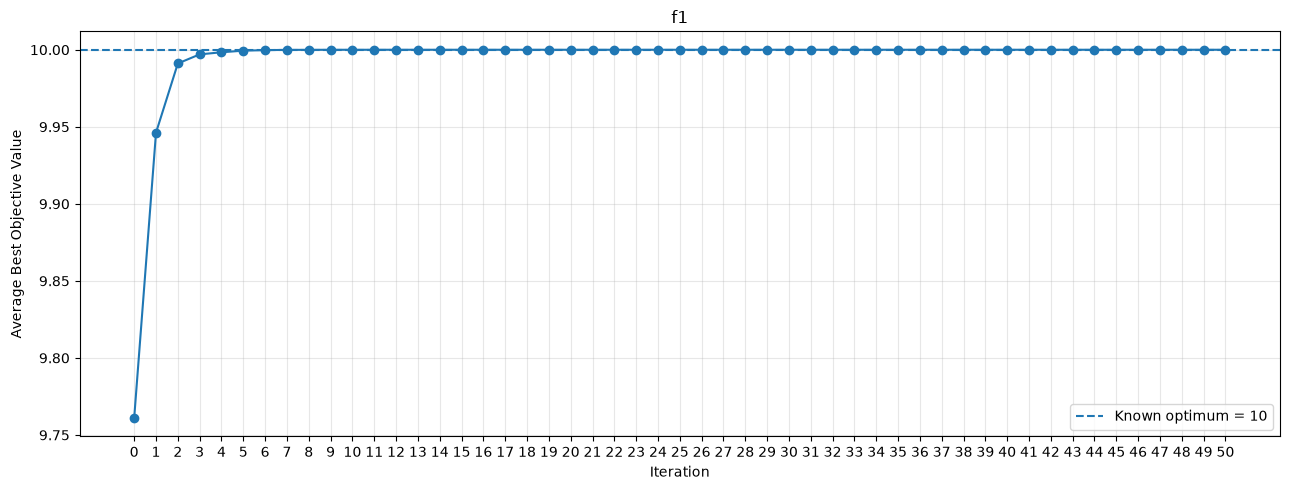

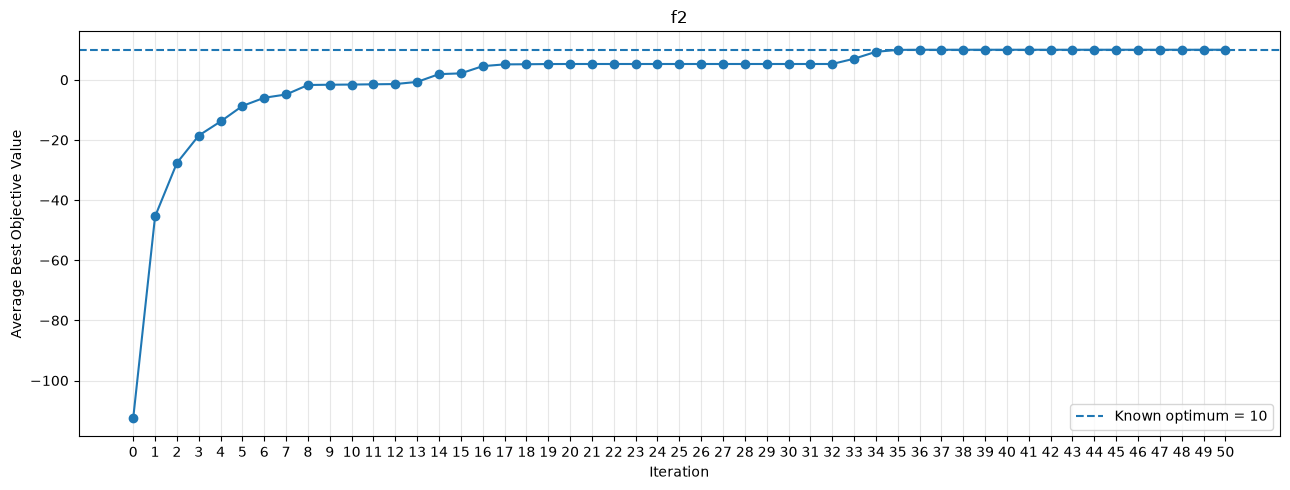

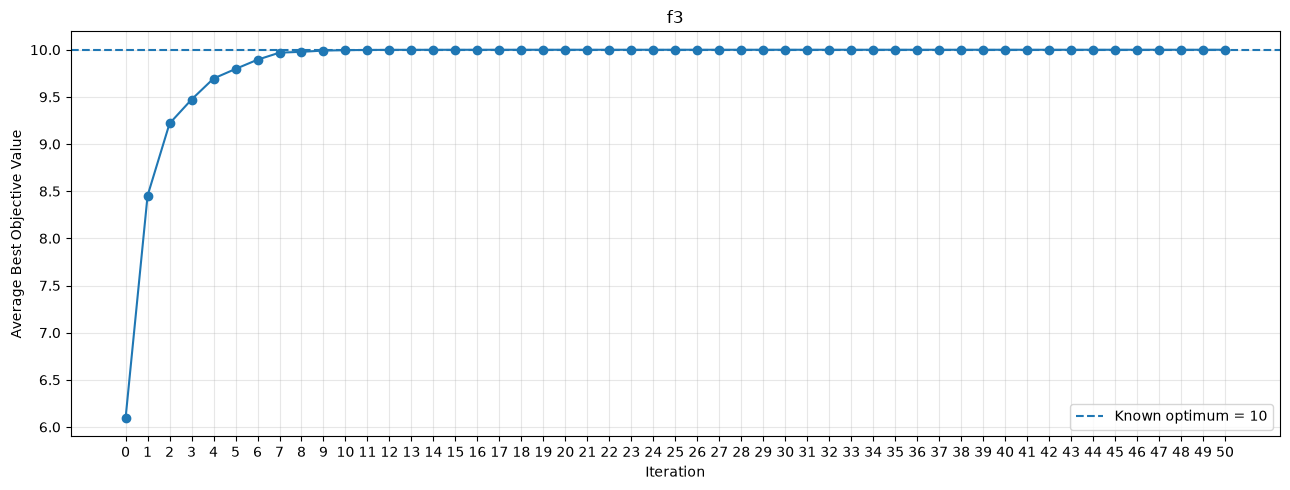

In [7]:
mean_history = {
    function: [
        statistics.mean(result["history"][i] for result in runs)
        for i in range(ITERATIONS + 1)
    ]
    for function, runs in results.items()
}

for function, history in mean_history.items():
    optimum = FUNCTIONS[function][3]
    plt.figure(figsize=(13, 5))

    plt.plot(
        range(ITERATIONS + 1),
        history,
        marker="o"
    )

    plt.axhline(
        y=optimum,
        linestyle="--",
        label=f"Known optimum = {optimum}"
    )

    plt.title(function)
    plt.xlabel("Iteration")
    plt.ylabel("Average Best Objective Value")
    plt.xticks(range(ITERATIONS + 1))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()